# 01 — Data and preparation

Our dataset comes from TCGA-BRCA PanCancer Atlas. It contains gene-expression profiles and clinical information for breast cancer samples. In the original expression matrix, columns are samples and rows are genes.

We use the data to study immune profiles and predict molecular subtypes. The RSEM values have already been normalized by the data provider.


In [1]:
from pathlib import Path
import csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold



## Paths and reproducibility

Study files are read from the project folder or `data/raw`. Intermediate data and figures are saved separately. A fixed seed controls random sampling.


In [2]:
ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
STUDY = ROOT / 'brca_tcga_pan_can_atlas_2018'
if not STUDY.exists():
    STUDY = ROOT / 'data' / 'raw' / 'brca_tcga_pan_can_atlas_2018'
OUT = ROOT / 'reports' / 'figures'
INTERIM = ROOT / 'data' / 'interim'
for folder in (OUT, INTERIM, ROOT / 'report'):
    folder.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', font_scale=1.05)
SEED = 42

files = [
    'data_mrna_seq_v2_rsem.txt',
    'data_clinical_patient.txt',
    'data_clinical_sample.txt',
]


## Reading the expression matrix

We check that the original column names are unique, then load the gene annotations and expression values. The first two columns identify genes; the remaining columns contain sample profiles.


In [ ]:
expression_file = STUDY / files[0]
with expression_file.open(encoding='utf-8') as stream:
    header = next(csv.reader(stream, delimiter='\t'))
raw = pd.read_csv(expression_file, sep='\t')
sample_ids = header[2:]
values = raw.iloc[:, 2:].apply(pd.to_numeric, errors='raise')


## Matching expression and clinical data

We match the expression profiles to the clinical records using sample and patient IDs. We also check for duplicate IDs and confirm that all samples are primary tumours.


In [ ]:
sample = pd.read_csv(STUDY / files[2], sep='\t', comment='#')
patient = pd.read_csv(STUDY / files[1], sep='\t', comment='#')
clinical = sample.merge(patient, on='PATIENT_ID', how='left', validate='many_to_one')
clinical = clinical.set_index('SAMPLE_ID').loc[sample_ids]
print(f'Matrice originale: {len(raw):,} righe geniche × {len(sample_ids):,} campioni')
display(raw.iloc[:5, :5])

Matrice originale: 20,531 righe geniche × 1,082 campioni


,Hugo_Symbol,Entrez_Gene_Id,TCGA-3C-AAAU-01,TCGA-3C-AALI-01,TCGA-3C-AALJ-01
0,NaN,100130426,0.0000,0.0000,0.9066
1,NaN,100133144,16.3644,9.2659,11.6228
2,UBE2Q2P2,100134869,12.9316,17.3790,9.2294
3,HMGB1P1,10357,52.1503,69.7553,154.2970
4,NaN,10431,408.0760,563.8930,1360.8300


## Clinical variables by subtype

The following cells summarize age, pathological stage, vital status and observation time. We use the clinical records matched to the 1,082 expression profiles. Percentages are calculated within each subtype.


In [5]:
# Individual descriptive figures: clinical information aligned by sample ID.
root=Path.cwd() if (Path.cwd()/'reports').exists() else Path.cwd().parent
out=root/'reports'/'figures';out.mkdir(parents=True,exist_ok=True)
bg='#efefef';blue='#326785';navy='#143B63';orange='#CC8545'
sns.set_theme(style='whitegrid',font_scale=1.1,rc={'font.family':'STIXGeneral','mathtext.fontset':'stix','figure.facecolor':bg,'axes.facecolor':bg,'savefig.facecolor':bg,'grid.alpha':.2})
df=clinical.copy();names={'BRCA_LumA':'LumA','BRCA_LumB':'LumB','BRCA_Basal':'Basal','BRCA_Her2':'HER2','BRCA_Normal':'Normal-like'}
order=['LumA','LumB','Basal','HER2','Normal-like'];df['group']=df.SUBTYPE.map(names).fillna('Unknown')
stage=df['AJCC_PATHOLOGIC_TUMOR_STAGE'].fillna('').astype(str).str.upper().str.strip()
df['stage_group']=stage.map(lambda x:'IV' if x.startswith('STAGE IV') else 'III' if x.startswith('STAGE III') else 'II' if x.startswith('STAGE II') else 'I' if x.startswith('STAGE I') else 'Unknown')
df['age_num']=pd.to_numeric(df.AGE,errors='coerce');df['obs_months']=pd.to_numeric(df.OS_MONTHS,errors='coerce')
def boxpoints(series,groups,xlabel,path):
 fig,ax=plt.subplots(figsize=(9.4,5.5));rng=np.random.default_rng(42)
 arrays=[series[df.group.eq(g)].dropna().to_numpy() for g in groups]
 for i,a in enumerate(arrays,1):ax.scatter(a,i+rng.uniform(-.18,.18,len(a)),s=9,alpha=.22,color=blue,edgecolors='none',zorder=1)
 b=ax.boxplot(arrays,vert=False,notch=True,showfliers=True,patch_artist=True,positions=np.arange(1,len(groups)+1),boxprops={'facecolor':'#ADCBD8','edgecolor':navy},medianprops={'color':navy,'linewidth':1.8},flierprops={'marker':'o','markersize':3,'markerfacecolor':orange,'markeredgecolor':orange,'alpha':.8})
 ax.set_yticks(range(1,len(groups)+1),[f'{g} (n={len(a)})' for g,a in zip(groups,arrays)]);ax.invert_yaxis();ax.set_xlabel(xlabel);sns.despine(ax=ax);fig.tight_layout();fig.savefig(out/path,dpi=180);plt.show()


### Age at diagnosis

Each point represents a sample. The boxes summarize the distribution, and the orange markers show values outside the boxplot whiskers.


<ipython-input-1-1c3c31b1d215>:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  b=ax.boxplot(arrays,vert=False,notch=True,showfliers=True,patch_artist=True,positions=np.arange(1,len(groups)+1),boxprops={'facecolor':'#ADCBD8','edgecolor':navy},medianprops={'color':navy,'linewidth':1.8},flierprops={'marker':'o','markersize':3,'markerfacecolor':orange,'markeredgecolor':orange,'alpha':.8})


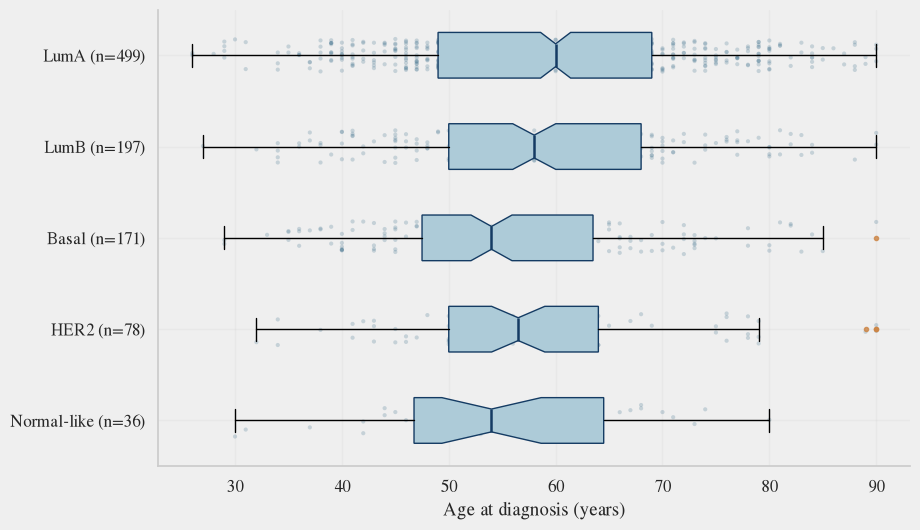

In [6]:
boxpoints(df.age_num,order,'Age at diagnosis (years)','101_age_by_subtype.png')


### Pathological stage

We group the recorded stages into I–IV and an unknown category. Each horizontal bar adds up to 100% of the samples in that subtype.


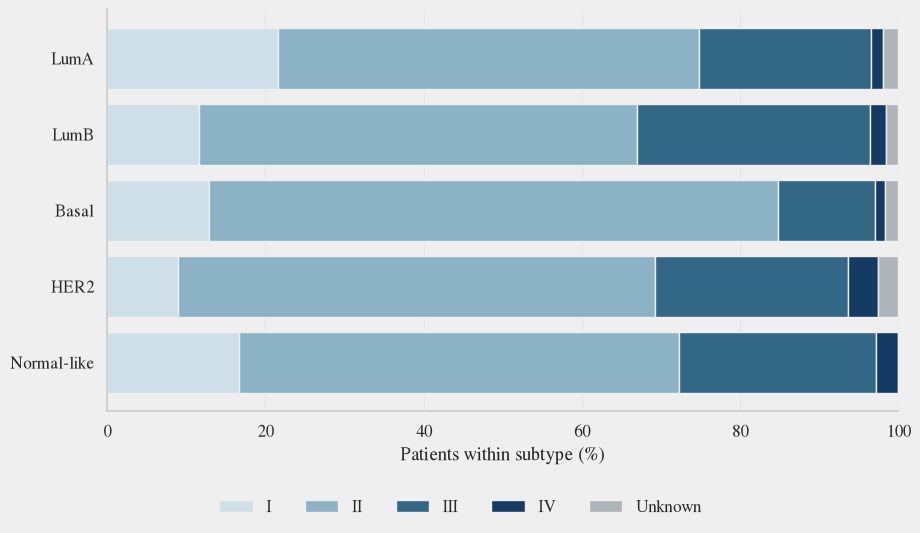

In [7]:
tab=pd.crosstab(df.group,df.stage_group).reindex(index=order,columns=['I','II','III','IV','Unknown'],fill_value=0);pct=tab.div(tab.sum(axis=1),axis=0)*100
fig,ax=plt.subplots(figsize=(9.4,5.5));left=np.zeros(len(order))
for k,color in zip(pct.columns,['#CEDFE7','#8BB3C5','#326785','#143B63','#AEB5B9']):
 v=pct[k].to_numpy();ax.barh(order,v,left=left,color=color,edgecolor=bg,label=k);left+=v
ax.invert_yaxis();ax.set(xlim=(0,100),xlabel='Patients within subtype (%)');fig.legend(*ax.get_legend_handles_labels(),ncol=5,frameon=False,loc='lower center',bbox_to_anchor=(.5,.015));sns.despine(ax=ax);fig.tight_layout(rect=[0,.10,1,1]);fig.savefig(out/'102_stage_by_subtype.png',dpi=180);plt.show()


### Recorded vital status

This compares the recorded status at last follow-up. It does not account for how long each person was followed and is not a survival analysis.


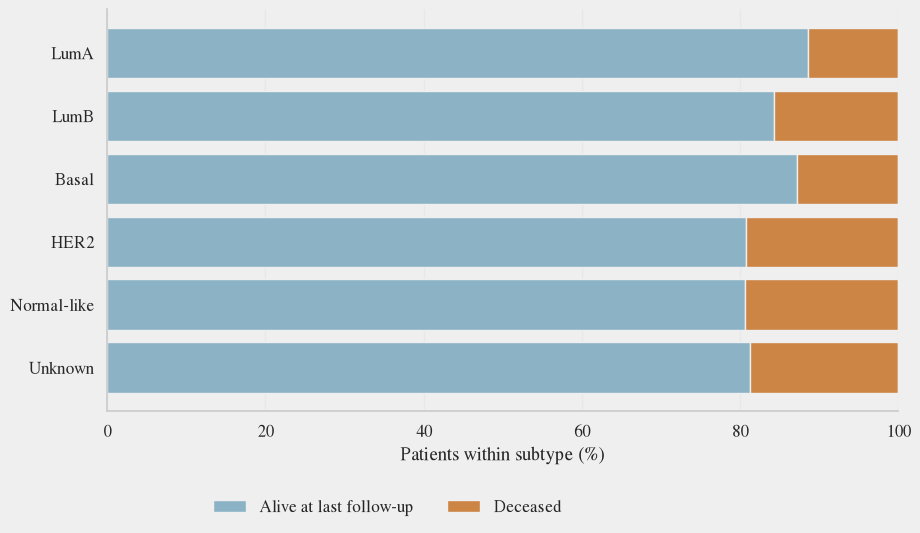

In [8]:
status=df.OS_STATUS.map({'0:LIVING':'Alive at last follow-up','1:DECEASED':'Deceased'}).fillna('Unknown');groups=order+['Unknown']
tab=pd.crosstab(df.group,status).reindex(index=groups,columns=['Alive at last follow-up','Deceased','Unknown'],fill_value=0);pct=tab.div(tab.sum(axis=1),axis=0)*100
fig,ax=plt.subplots(figsize=(9.4,5.5));left=np.zeros(len(groups))
for k,color in [('Alive at last follow-up','#8BB3C5'),('Deceased',orange),('Unknown','#AEB5B9')]:
 v=pct[k].to_numpy();ax.barh(groups,v,left=left,color=color,edgecolor=bg,label=k);left+=v
ax.invert_yaxis();ax.set(xlim=(0,100),xlabel='Patients within subtype (%)');handles, legend_labels = ax.get_legend_handles_labels();legend=fig.legend(handles,legend_labels,ncol=3,frameon=False,loc='lower center',bbox_to_anchor=(.5,.015));
if tab['Unknown'].sum()==0:
 legend.get_texts()[-1].set_visible(False);legend.legend_handles[-1].set_visible(False)
sns.despine(ax=ax);fig.tight_layout(rect=[0,.10,1,1]);fig.savefig(out/'103_status_by_subtype.png',dpi=180);plt.show()


### Observation time

The boxplots show months to death or last follow-up. The groups have different follow-up lengths.


<ipython-input-1-1c3c31b1d215>:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  b=ax.boxplot(arrays,vert=False,notch=True,showfliers=True,patch_artist=True,positions=np.arange(1,len(groups)+1),boxprops={'facecolor':'#ADCBD8','edgecolor':navy},medianprops={'color':navy,'linewidth':1.8},flierprops={'marker':'o','markersize':3,'markerfacecolor':orange,'markeredgecolor':orange,'alpha':.8})


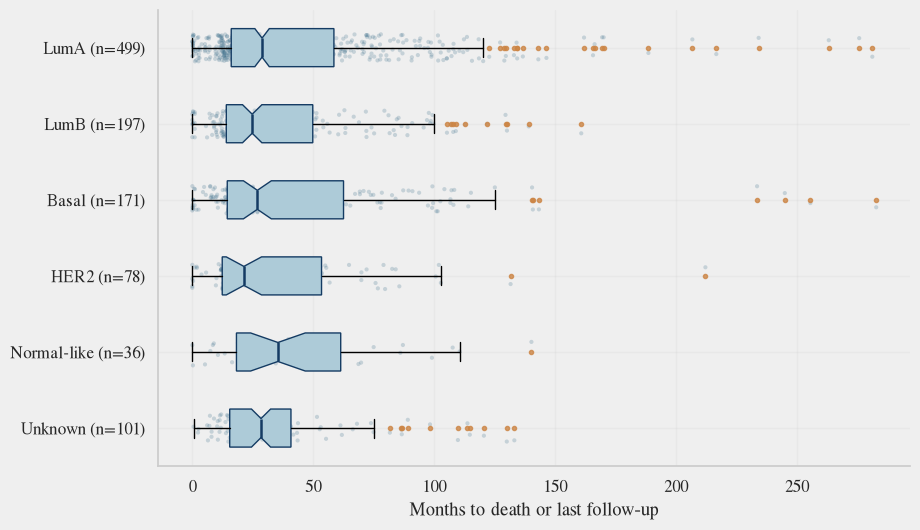

In [9]:
boxpoints(df.obs_months,groups,'Months to death or last follow-up','104_followup_by_subtype.png')


### Numerical summaries

These counts and medians support the clinical figures above.


In [10]:
print('Median age by subtype:',df.groupby('group').age_num.median().round(1).to_dict())
print('Stage II % by subtype:',(pd.crosstab(df.group,df.stage_group).div(df.group.value_counts(),axis=0)*100).round(1).to_string())
print('Vital status counts by subtype:',tab.to_string())


Median age by subtype: {'Basal': 54.0, 'HER2': 56.5, 'LumA': 60.0, 'LumB': 58.0, 'Normal-like': 54.0, 'Unknown': 59.0}
Stage II % by subtype: stage_group     I    II   III   IV  Unknown
group                                      
Basal        12.9  71.9  12.3  1.2      1.8
HER2          9.0  60.3  24.4  3.8      2.6
LumA         21.6  53.1  21.8  1.4      2.0
LumB         11.7  55.3  29.4  2.0      1.5
Normal-like  16.7  55.6  25.0  2.8      0.0
Unknown      13.9  50.5  32.7  2.0      1.0
Vital status counts by subtype: OS_STATUS    Alive at last follow-up  Deceased  Unknown
group                                                  
LumA                             442        57        0
LumB                             166        31        0
Basal                            149        22        0
HER2                              63        15        0
Normal-like                       29         7        0
Unknown                           82        19        0


## Dataset dimensions

The clinical files contain 1,084 samples and patients. The expression file has profiles for 1,082 of those samples, plus two gene-annotation columns.


In [11]:
print('Clinical samples:',len(sample),'| attributes:',sample.shape[1])
print('Patients:',len(patient),'| attributes:',patient.shape[1])
print('Expression matrix:',len(raw),'gene rows ×',len(sample_ids),'sample profiles')


Clinical samples: 1084 | attributes: 19
Patients: 1084 | attributes: 38
Expression matrix: 20531 gene rows × 1082 sample profiles


## Checking gene annotations

We list rows with missing or repeated Entrez identifiers and save the exclusions. The following quality checks use the original expression values.


In [12]:
array = values.to_numpy(dtype=np.float64)
gene_id = raw['Entrez_Gene_Id']
ambiguous = gene_id.duplicated(keep=False) | gene_id.isna()
duplicate_annotations = raw.loc[ambiguous, ['Hugo_Symbol', 'Entrez_Gene_Id']]
display(duplicate_annotations)
duplicate_annotations.to_csv(INTERIM / 'ambiguous_gene_annotations.csv', index=False)



,Hugo_Symbol,Entrez_Gene_Id
495,PALM2AKAP2,445815
949,ARHGAP42,143872
1642,BTBD8,284697
1683,C10orf113,10529
1691,C10orf12,84458
1695,C10orf131,387707
1833,C12orf74,440107
1871,C14orf139,161176
1910,C14orf49,161176
2012,C17orf47,5414


## Expression-matrix quality

We check for missing, infinite and negative values and count constant genes. The report records 20,531 original gene rows, no missing, infinite or negative cells, and 282 constant rows, all zero.


In [ ]:
qc = {
    'samples': len(sample_ids),
    'gene_rows_original': len(raw),
    'missing_cells': int(np.isnan(array).sum()),
    'infinite_cells': int(np.isinf(array).sum()),
    'negative_cells': int((array < 0).sum()),
    'duplicated_entrez_extra_rows': int(gene_id.duplicated().sum()),
    'ambiguous_annotation_rows_excluded': int(ambiguous.sum()),
    'missing_gene_symbols': int(raw['Hugo_Symbol'].isna().sum()),
    'constant_gene_rows_original': int(values.nunique(axis=1, dropna=True).le(1).sum()),
    'all_zero_gene_rows_original': int(values.eq(0).all(axis=1).sum()),
}
display(pd.Series(qc).to_frame('valore'))



,valore
samples,1082
gene_rows_original,20531
missing_cells,0
infinite_cells,0
negative_cells,0
duplicated_entrez_extra_rows,26
ambiguous_annotation_rows_excluded,50
missing_gene_symbols,13
constant_gene_rows_original,282
all_zero_gene_rows_original,282


## Gene identifiers and transformation

We remove 50 rows with missing or duplicated Entrez IDs, leaving 20,481 genes. We then transpose the matrix so that each row is a sample and each column is a gene, and apply the log transformation.


In [ ]:
usable = ~ambiguous
X_rsem = values.loc[usable].T.copy()
X_rsem.columns = gene_id.loc[usable].astype('int64').astype(str).tolist()
X_rsem.index.name = 'SAMPLE_ID'
X_log = np.log2(1.0 + X_rsem).astype('float32')
qc['gene_features_unique'] = X_log.shape[1]
qc['duplicate_expression_profiles'] = int(X_log.duplicated().sum())
print('Matrice per le fasi successive:', X_log.shape)

Matrice per le fasi successive: (1082, 20481)


## Distribution before and after the logarithm

Both panels use all values of the prepared expression matrix (1,082 samples × 20,481 genes). Original values are reconstructed from log2(1 + RSEM). Both frequency axes have identical logarithmic limits; bin widths differ.


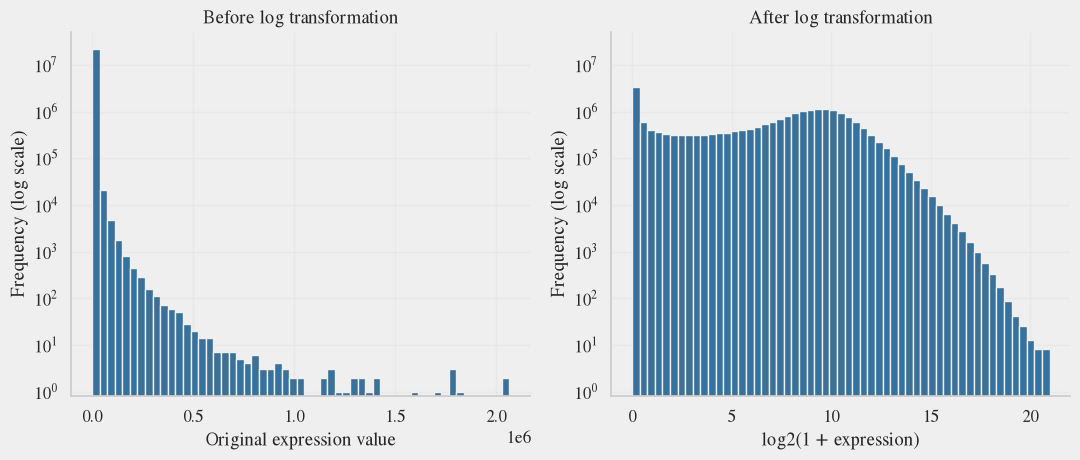

In [15]:
# Before and after the logarithm: same values and common y-axis.
sns.set_theme(style='whitegrid',font_scale=1.1,rc={'font.family':'STIXGeneral','mathtext.fontset':'stix','figure.facecolor':'#efefef','axes.facecolor':'#efefef','savefig.facecolor':'#efefef','grid.alpha':.18})
logvals=X_log.to_numpy().ravel().astype(float);rawvals=np.expm1(logvals*np.log(2))
fig,axes=plt.subplots(1,2,figsize=(11,4.8),sharey=True)
axes[0].hist(rawvals,bins=55,color='#39719a',edgecolor='#efefef');axes[0].set(title='Before log transformation',xlabel='Original expression value',ylabel='Frequency (log scale)',yscale='log')
axes[1].hist(logvals,bins=55,color='#39719a',edgecolor='#efefef');axes[1].set(title='After log transformation',xlabel='log2(1 + expression)',ylabel='Frequency (log scale)',yscale='log')
axes[1].tick_params(labelleft=True)
axes[0].set_ylim(bottom=.8)
for ax in axes:sns.despine(ax=ax)
fig.tight_layout();fig.savefig(OUT/'110_expression_before_after.png',dpi=180);plt.show()


## Subtype composition

Luminal A is the largest subtype, with 499 samples. Normal-like has 36. It is a molecular subtype of tumour samples. The chart also shows the 101 samples without a subtype label.


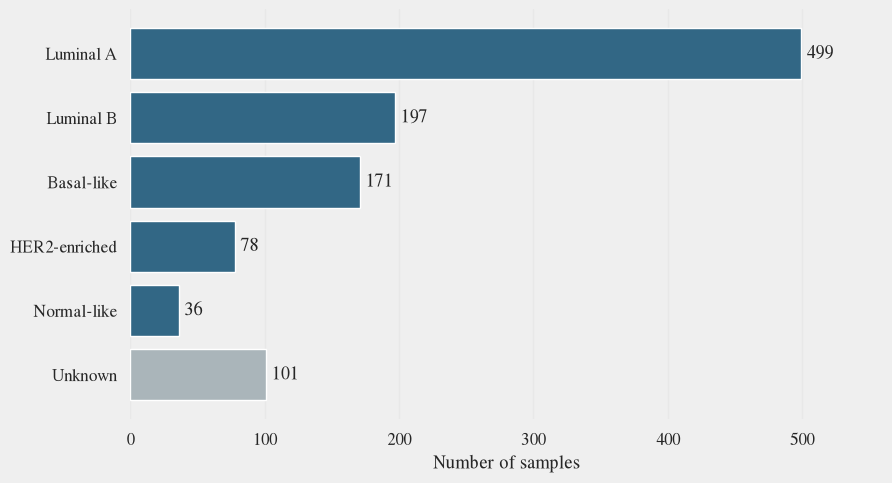

In [16]:
plt.rcParams.update({'figure.facecolor':'#efefef','axes.facecolor':'#efefef','savefig.facecolor':'#efefef'})
names = {'BRCA_Basal':'Basal-like','BRCA_Her2':'HER2-enriched','BRCA_LumA':'Luminal A','BRCA_LumB':'Luminal B','BRCA_Normal':'Normal-like'}
order = ['Luminal A','Luminal B','Basal-like','HER2-enriched','Normal-like']
labels = clinical.SUBTYPE.map(names).fillna('Unknown')
counts = labels.value_counts().reindex(order + ['Unknown'], fill_value=0)
fig, ax = plt.subplots(figsize=(9,5))
bars=ax.barh(counts.index[::-1], counts.values[::-1], color=['#aab5ba']+['#326785']*5, edgecolor='white')
ax.bar_label(bars, padding=4); ax.set(xlabel='Number of samples', xlim=(0, 560))
ax.grid(axis='y',visible=False); sns.despine(ax=ax,left=True,bottom=True)
fig.subplots_adjust(left=.149, right=.985, bottom=.14, top=.96); fig.savefig(OUT/'79_en_subtypes_unknown_last.png',dpi=180); plt.show()


## CD8A expression before clustering

CD8A illustrates how expression varies across known subtypes. Points show individual samples; orange markers indicate observations outside the boxplot whiskers.


CD8A medians: {'Basal-like': 7.630000114440918, 'HER2-enriched': 7.409999847412109, 'Luminal A': 7.199999809265137, 'Luminal B': 6.96999979019165, 'Normal-like': 8.170000076293945}


<ipython-input-1-69e3fe056577>:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(arrays,vert=False,notch=True,showfliers=True,patch_artist=True,boxprops={'facecolor':'#ADCBD8','edgecolor':'#143B63'},medianprops={'color':'#143B63','linewidth':1.8},flierprops={'marker':'o','markersize':3,'markerfacecolor':'#CC8545','markeredgecolor':'#CC8545','alpha':.8})


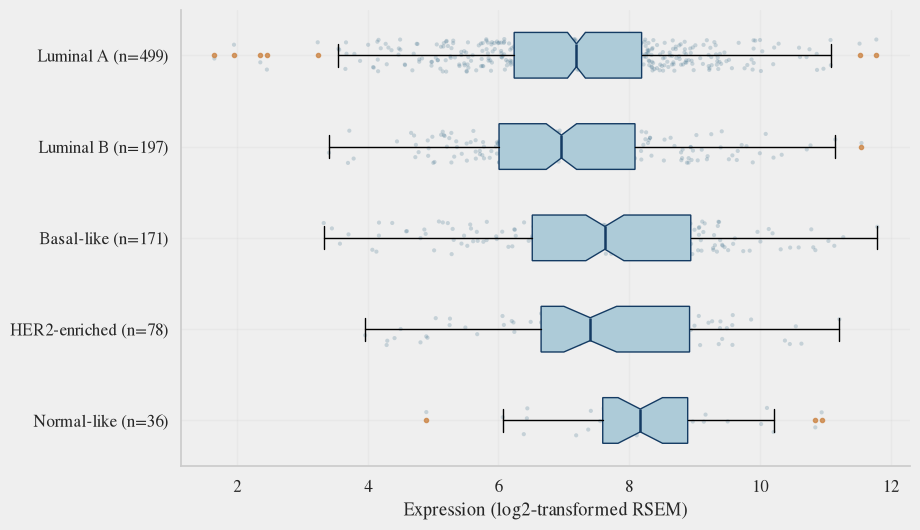

In [17]:
# Individual gene expression plots; points show samples and orange points show outliers.
plt.rcParams.update({'font.family':'STIXGeneral','mathtext.fontset':'stix','figure.facecolor':'#efefef','axes.facecolor':'#efefef','savefig.facecolor':'#efefef'})
names={'BRCA_Basal':'Basal-like','BRCA_Her2':'HER2-enriched','BRCA_LumA':'Luminal A','BRCA_LumB':'Luminal B','BRCA_Normal':'Normal-like'}
order=['Luminal A','Luminal B','Basal-like','HER2-enriched','Normal-like']
annotations=raw.loc[usable,['Hugo_Symbol','Entrez_Gene_Id']]
for gene in ['CD8A']:
 gene_id=str(int(annotations.loc[annotations.Hugo_Symbol.eq(gene),'Entrez_Gene_Id'].iloc[0]))
 tmp=pd.DataFrame({'subtype':clinical.SUBTYPE.map(names),'value':X_log[gene_id]}).dropna();arrays=[tmp.loc[tmp.subtype.eq(g),'value'].to_numpy() for g in order]
 fig,ax=plt.subplots(figsize=(9.4,5.5));rng=np.random.default_rng(42)
 for i,a in enumerate(arrays,1):ax.scatter(a,i+rng.uniform(-.18,.18,len(a)),s=9,alpha=.22,color='#326785',edgecolors='none',zorder=1)
 ax.boxplot(arrays,vert=False,notch=True,showfliers=True,patch_artist=True,boxprops={'facecolor':'#ADCBD8','edgecolor':'#143B63'},medianprops={'color':'#143B63','linewidth':1.8},flierprops={'marker':'o','markersize':3,'markerfacecolor':'#CC8545','markeredgecolor':'#CC8545','alpha':.8})
 ax.set_yticks(range(1,6),[f'{g} (n={len(a)})' for g,a in zip(order,arrays)]);ax.invert_yaxis();ax.set_xlabel('Expression (log2-transformed RSEM)');sns.despine(ax=ax);fig.tight_layout();fig.savefig(OUT/f'107_{gene}_subtypes.png',dpi=180);plt.show()
 print(gene,'medians:',tmp.groupby('subtype').value.median().round(2).to_dict())


## Classification split

We use all 1,082 samples for clustering. For classification, we keep the 981 samples with a known subtype and divide them into 784 training and 197 test samples. The split is stratified and uses seed 42.

We also check that no patient appears in both sets.


In [18]:
labelled = clinical.loc[clinical['SUBTYPE'].notna()].copy()
train_ids, test_ids = train_test_split(
    labelled.index.to_numpy(), test_size=.20, random_state=SEED,
    stratify=labelled['SUBTYPE'],
)


## Split manifest and folds

The manifest keeps track of the patient, subtype and split for each sample. We assign the training samples to five stratified folds for cross-validation.


In [ ]:
manifest = clinical[['PATIENT_ID', 'SUBTYPE']].copy()
manifest['split'] = 'unlabelled'
manifest.loc[train_ids, 'split'] = 'train'
manifest.loc[test_ids, 'split'] = 'test'
manifest['validation_fold'] = pd.Series(pd.NA, index=manifest.index, dtype='Int64')
train = manifest.loc[train_ids]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (_, val_positions) in enumerate(cv.split(train.index, train['SUBTYPE'])):
    manifest.loc[train.index[val_positions], 'validation_fold'] = fold

## Checking and saving the split

The table shows the number of samples per class in each set. Results for rare classes require particular care.


In [20]:
split_counts = pd.crosstab(manifest['SUBTYPE'], manifest['split']).reindex(columns=['train', 'test'], fill_value=0)
display(split_counts)
qc.update(labelled_samples=len(labelled), train_samples=len(train_ids), test_samples=len(test_ids),
          unlabelled_samples=int(manifest['split'].eq('unlabelled').sum()))
manifest.to_csv(INTERIM / 'classification_split.csv')
split_counts.to_csv(INTERIM / 'split_class_counts.csv')

split,train,test
SUBTYPE,,
BRCA_Basal,137,34
BRCA_Her2,62,16
BRCA_LumA,399,100
BRCA_LumB,157,40
BRCA_Normal,29,7


## Data for the next notebooks

We save the transformed matrix, aligned metadata and gene annotations. In classification, gene selection and scaling will be fitted separately within each training fold.


In [21]:
X_log.to_parquet(INTERIM / 'expression_log2_rsem.parquet')
clinical.to_parquet(INTERIM / 'clinical_aligned.parquet')
raw.loc[usable, ['Hugo_Symbol', 'Entrez_Gene_Id']].to_csv(INTERIM / 'gene_annotations.csv', index=False)